In [2]:
from PIL import Image
import numpy as np
from sklearn.linear_model import LogisticRegression
from pathlib import Path
import matplotlib.pyplot as plt


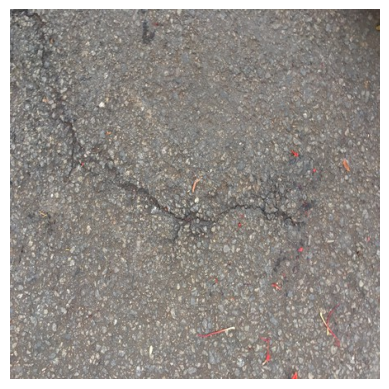

(448, 448)


In [3]:
path = Path("../data/image/Cracks/IMG_8504 resized_448.jpg")
img = Image.open(path)
plt.imshow(img)
plt.axis("off")
plt.show()

print(img.size)

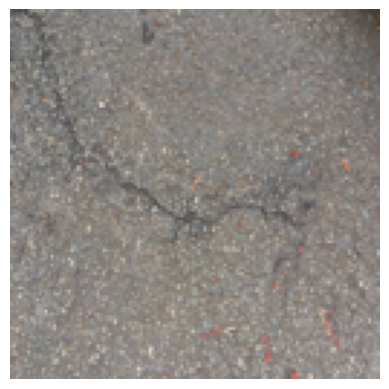

(128, 128)


In [4]:
img_resize = img.resize((128,128))
plt.imshow(img_resize)
plt.axis("off")
plt.show()

print(img_resize.size)

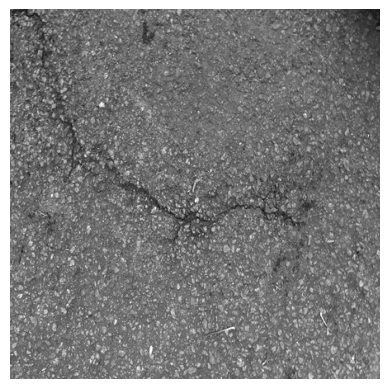

In [5]:
gray = img.convert("L")

plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

In [8]:
pixels = np.array(img)
print(pixels.shape)
print(pixels)

(448, 448, 3)
[[[134 134 136]
  [112 112 114]
  [130 130 132]
  ...
  [ 70  61  56]
  [ 69  58  54]
  [ 70  59  55]]

 [[ 86  86  88]
  [ 83  83  85]
  [ 94  94  96]
  ...
  [ 68  59  54]
  [ 68  57  53]
  [ 69  58  54]]

 [[105 105 107]
  [ 93  93  95]
  [ 77  77  79]
  ...
  [ 68  59  54]
  [ 67  56  52]
  [ 68  57  53]]

 ...

 [[138 127 123]
  [137 126 122]
  [159 148 144]
  ...
  [159 154 150]
  [149 141 139]
  [140 132 130]]

 [[144 133 131]
  [139 128 126]
  [142 131 129]
  ...
  [151 146 143]
  [145 137 135]
  [142 134 132]]

 [[137 126 124]
  [136 125 123]
  [131 120 118]
  ...
  [137 132 129]
  [136 128 126]
  [140 132 130]]]


In [17]:
pixels = np.array(gray)
print(pixels.shape)
print(pixels)

(448, 448)
[[134 112 130 ...  63  61  62]
 [ 86  83  94 ...  61  60  61]
 [105  93  77 ...  61  59  60]
 ...
 [130 129 151 ... 155 143 134]
 [136 131 134 ... 147 139 136]
 [129 128 123 ... 133 130 134]]


In [18]:
#before normali.
print("min: " ,pixels.min())
print("max: " ,pixels.max())

min:  37
max:  254


In [19]:
#normalize
normalize = pixels / 255


In [20]:
#after normalize.
print("min: " ,normalize.min())
print("max: " ,normalize.max())

min:  0.1450980392156863
max:  0.996078431372549


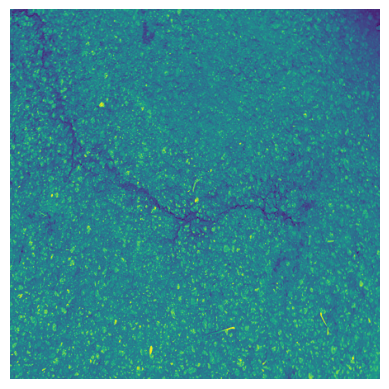

200704


In [21]:
plt.imshow(normalize)
plt.axis("off")
plt.show()

print(normalize.size)

In [23]:
print(type(normalize))

<class 'numpy.ndarray'>


In [26]:
features =normalize.flatten()

In [31]:
print(features.shape) #
print(normalize.shape)

(200704,)
(448, 448)


In [34]:
features.min()

np.float64(0.1450980392156863)

In [33]:

features.max()

np.float64(0.996078431372549)

In [35]:
import os

dataset_path = "../data/image"

print(os.listdir(dataset_path))

['Cracks', 'NonCracks']


In [36]:
crack_path = "../data/image/Cracks"
noncrack_path = "../data/image/NonCracks"

print(os.listdir(crack_path)[:5])
print(os.listdir(noncrack_path)[:5])

['IMG_20180513_164959951_HDR resized_448.jpg', 'IMG_20180513_165129852_HDR resized_448.jpg', 'IMG_20180513_165150613_HDR resized_448.jpg', 'IMG_20180513_165345878_HDR resized_448.jpg', 'IMG_20180513_165349788_HDR resized_448.jpg']
['IMG_20180705_130729936 resized_448.jpg', 'IMG_20180705_130731751 resized_448.jpg', 'IMG_20180705_130732496 resized_448.jpg', 'IMG_20180705_130732993 resized_448.jpg', 'IMG_20180705_130733329 resized_448.jpg']


In [37]:
import os

dataset_path = "../data/image"

crack_path = os.path.join(dataset_path, "Cracks")
noncrack_path = os.path.join(dataset_path, "NonCracks")

crack_images = os.listdir(crack_path)
noncrack_images = os.listdir(noncrack_path)

print("Crack images:", len(crack_images))
print("Non-crack images:", len(noncrack_images))

Crack images: 200
Non-crack images: 200


In [40]:
import os
import numpy as np
from PIL import Image

X = []
y = []

dataset_path = "../data/image"

# Crack = 1
# Not Crack = 0
classes = {
    "Cracks": 1,
    "NonCracks": 0
}

for folder, label in classes.items():

    folder_path = os.path.join(dataset_path, folder)

    for filename in os.listdir(folder_path):

        image_path = os.path.join(folder_path, filename)

        try:
            # Read image
            img = Image.open(image_path)

            # Resize
           # img = img.resize((128, 128))

            # Convert to grayscale
            img = img.convert("L")

            # Convert to NumPy
            img = np.array(img, dtype=np.float32)

            # Normalize 0–255 → 0–1
            img = img / 255.0

            # Flatten 128×128 → 16384
            img = img.flatten()

            X.append(img)
            y.append(label)

        except:
            print("Could not read:", image_path)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 200704)
y shape: (400,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (320, 200704)
Testing: (80, 200704)


In [42]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [43]:
y_pred = model.predict(X_test)

In [44]:
y_prob = model.predict_proba(X_test)

print(y_prob[:5])

[[0.95176274 0.04823729]
 [0.9003718  0.09962823]
 [0.72308636 0.27691367]
 [0.9790881  0.02091187]
 [0.31184447 0.68815553]]


In [45]:
print(model.classes_)

[0 1]


In [46]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Crack", "Crack"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6625

Classification Report:
              precision    recall  f1-score   support

   Not Crack       0.61      0.88      0.72        40
       Crack       0.78      0.45      0.57        40

    accuracy                           0.66        80
   macro avg       0.70      0.66      0.65        80
weighted avg       0.70      0.66      0.65        80


Confusion Matrix:
[[35  5]
 [22 18]]


In [47]:
def preprocess_image(image_path):

    img = Image.open(image_path)

    # Resize
    #img = img.resize((128, 128))

    # Grayscale
    img = img.convert("L")

    # NumPy
    img = np.array(img, dtype=np.float32)

    # Normalize
    img = img / 255.0

    # Flatten
    img = img.flatten()

    # Make 2D for sklearn
    img = img.reshape(1, -1)

    return img

In [49]:
new_image = preprocess_image("../data/image/Cracks/IMG_8504 resized_448.jpg")

prediction = model.predict(new_image)
probability = model.predict_proba(new_image)

if prediction[0] == 1:
    print("Crack")
else:
    print("Not Crack")

print("Probability:", probability)

Crack
Probability: [[0.00740886 0.99259114]]
